# 03 · Does a solar forecast improve the model?

Notebook 01 showed negative prices peaking around 14:00, which looks like solar, and notebook 02
showed the model has no input describing it. NESO publishes an hourly forecast of *embedded*
solar and wind (panels and turbines connected to local networks rather than the national grid),
with every past version archived. That lets us use it without peeking.

Two questions, in order:

1. **Is it new information?** The national demand forecast (NDF) is demand seen by the national
   grid, so it is *already reduced* by expected embedded solar. Solar may be partly baked in.
2. **Does it improve the model in £, on the validation window?** Same model and settings, with
   and without the four solar/embedded inputs, in a rolling backtest over the six months before
   the test year. The test year is not used to decide.

Availability rule: a NESO vintage counts from its timestamp + 2 hours (it takes up to ~85 min to
appear in the archive, and the timestamp's timezone is unconfirmed). See docs/data-sources.md.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import style

from flexcast.backtest import BacktestConfig, feature_table, run, summarise
from flexcast.features import EMBEDDED_COLUMNS, FEATURE_COLUMNS
from flexcast.history import History
from flexcast.models.lgbm import LGBMQuantile
from flexcast.settlement import LONDON
from flexcast.storage import Storage

style.use()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
history = History.load(Storage(f"file://{ROOT / 'data'}"))
print(
    f"embedded forecast rows: {len(history.embedded):,}, "
    f"vintages: {history.embedded.publish_time.nunique():,}"
)

# Validation window: the six months before the test year (same as the risk-aware alpha choice).
VAL_START, VAL_END, TRAIN_START = date(2025, 4, 21), date(2025, 10, 19), date(2024, 10, 20)
# LightGBM settings in force when this decision was made (before tuning in notebook 04), so the
# comparison reproduces exactly. The code defaults now hold the tuned settings.
PRE_TUNING = {"num_leaves": 31, "min_data_in_leaf": 50, "feature_fraction": 0.9, "lambda_l2": 0.0}
PRE_TUNING_ROUNDS = 300

embedded forecast rows: 2,100,592, vintages: 17,294


## 1. What the solar forecast looks like at decision time

rows with a solar forecast: 99.2%


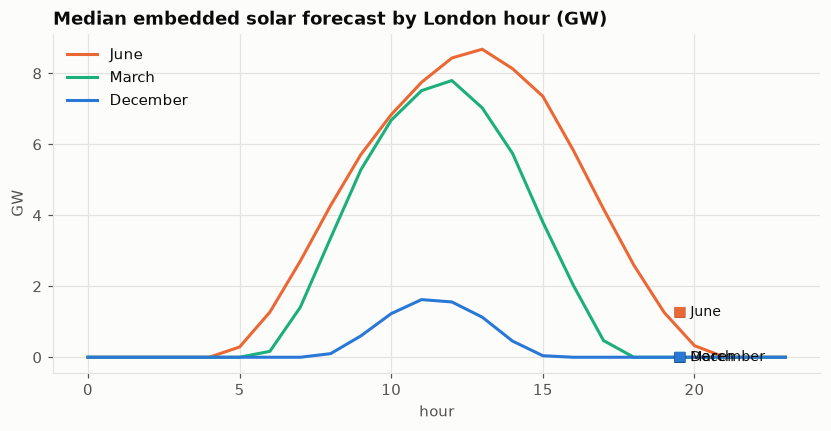

In [2]:
days = pd.date_range(TRAIN_START, VAL_END).date.tolist()
X, y, _ = feature_table(history, list(days), decision_at=pd.Timestamp("09:00").time())
df = X.assign(price=y.values).reset_index()
df["hour"] = df["start_time"].dt.tz_convert(LONDON).dt.hour
df["month"] = df["start_time"].dt.tz_convert(LONDON).dt.month
print(f"rows with a solar forecast: {df.solar.notna().mean():.1%}")

profile = df.groupby(["month", "hour"])["solar"].median().unstack(0) / 1000
fig, ax = plt.subplots()
for month, color, label in (
    (6, style.ORANGE, "June"),
    (3, style.AQUA, "March"),
    (12, style.BLUE, "December"),
):
    if month in profile:
        ax.plot(profile.index, profile[month], color=color, label=label)
        style.label_end(ax, profile.index[-1] - 4, profile[month].iloc[-5], label, color)
ax.set(title="Median embedded solar forecast by London hour (GW)", xlabel="hour", ylabel="GW")
ax.legend(loc="upper left")
plt.show()

Up to ~12 GW at a summer midday, around half of national demand, and close to zero in winter.

## 2. Is it already inside the demand forecast?

If NDF fully accounted for solar, then once you know demand-minus-wind, solar should tell you
nothing more about the price. Test it: within narrow bands of demand-minus-wind, compare the
price when solar is high vs low (daytime hours only).

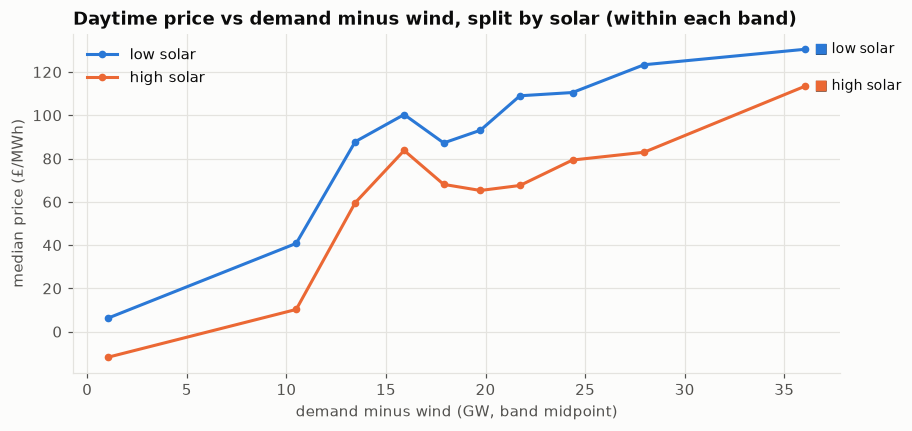

median price gap, low vs high solar at the same demand-minus-wind: £28.0/MWh


In [3]:
day = df[df.hour.between(9, 16)].dropna(subset=["solar", "residual_demand"]).copy()
day["band"] = pd.qcut(day["residual_demand"], 10)
day["solar_level"] = day.groupby("band", observed=True)["solar"].transform(
    lambda s: pd.qcut(s, 3, labels=["low solar", "mid", "high solar"])
)
table = day.pivot_table(
    index="band", columns="solar_level", values="price", aggfunc="median", observed=True
)

fig, ax = plt.subplots()
mid = [iv.mid / 1000 for iv in table.index]
for col, color in (("low solar", style.BLUE), ("high solar", style.ORANGE)):
    ax.plot(mid, table[col], color=color, marker="o", markersize=4, label=col)
    style.label_end(ax, mid[-1], table[col].iloc[-1], col, color)
ax.set(
    title="Daytime price vs demand minus wind, split by solar (within each band)",
    xlabel="demand minus wind (GW, band midpoint)",
    ylabel="median price (£/MWh)",
)
ax.legend(loc="upper left")
plt.show()
gap = (table["low solar"] - table["high solar"]).median()
print(f"median price gap, low vs high solar at the same demand-minus-wind: £{gap:.1f}/MWh")

A gap means solar carries information the demand forecast doesn't: the same headline demand
number goes with different prices depending on how much of the day is solar-driven (cheap,
certain midday supply, steeper evening ramp). So it's worth testing in the model.

## 3. Does it improve the model? Rolling backtest on the validation window

Identical LightGBM settings; the only difference is the input list. Retrained weekly on all
days known at each decision, exactly like the main backtest.

In [4]:
cfg = BacktestConfig(
    test_start=VAL_START, test_end=VAL_END, train_start=TRAIN_START, validation_days=0
)
result = run(
    history,
    cfg,
    {
        "baseline (23 inputs)": lambda: LGBMQuantile(
            features=FEATURE_COLUMNS, params=PRE_TUNING, num_rounds=PRE_TUNING_ROUNDS
        ),
        "+ solar (27 inputs)": lambda: LGBMQuantile(
            features=FEATURE_COLUMNS + EMBEDDED_COLUMNS,
            params=PRE_TUNING,
            num_rounds=PRE_TUNING_ROUNDS,
        ),
    },
)
summary = summarise(result.daily)
summary.style.format("{:.2f}")

,days,gbp_per_year,pct_of_perfect,mae,pinball,coverage_80
strategy,,,,,,
perfect,182.00,238.61,100.00,0.00,0.00,1.00
+ solar (27 inputs),182.00,28.47,11.93,27.37,8.37,0.67
baseline (23 inputs),182.00,24.58,10.30,27.62,8.44,0.66


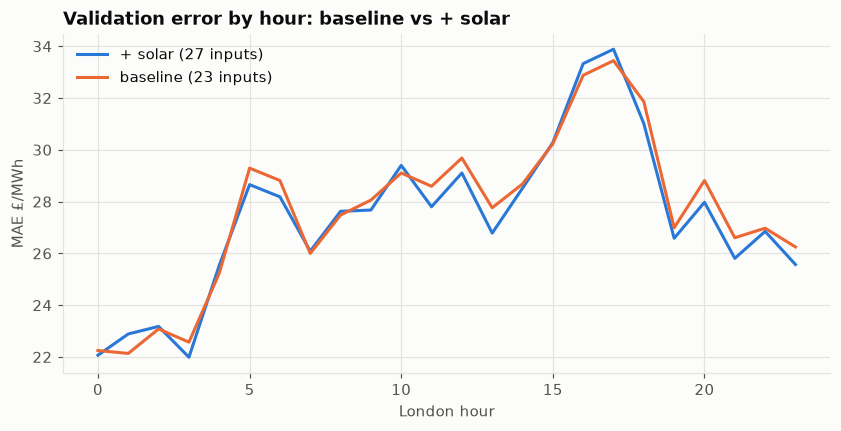

In [5]:
f = result.forecasts[result.forecasts.strategy != "perfect"].copy()
f["hour"] = f["start_time"].dt.tz_convert(LONDON).dt.hour
mae = f.assign(err=(f.p50 - f.actual).abs()).pivot_table(
    index="hour", columns="strategy", values="err"
)

fig, ax = plt.subplots()
for col, color in zip(mae.columns, (style.BLUE, style.ORANGE), strict=True):
    ax.plot(mae.index, mae[col], color=color, label=col)
ax.set(
    title="Validation error by hour: baseline vs + solar", xlabel="London hour", ylabel="MAE £/MWh"
)
ax.legend(loc="upper left")
plt.show()

In [6]:
wide = result.daily.pivot(index="target_date", columns="strategy", values="value_gbp")
diff = wide["+ solar (27 inputs)"] - wide["baseline (23 inputs)"]
print(
    f"days where + solar earned more: {(diff > 0).mean():.0%}; "
    f"total difference over {len(diff)} days: £{diff.sum():.2f} per battery"
)
boot = np.random.default_rng(0)
means = [boot.choice(diff.to_numpy(), len(diff)).mean() * 365 for _ in range(2000)]
lo, hi = np.percentile(means, [5, 95])
print(f"£/year difference, 90% bootstrap interval: £{lo:.1f} to £{hi:.1f}")

days where + solar earned more: 37%; total difference over 182 days: £1.94 per battery
£/year difference, 90% bootstrap interval: £-3.1 to £10.8


The bootstrap interval resamples days to show how much of the £ difference could be luck:
if it straddles zero, the gain isn't distinguishable from noise over six months.

## 4. What the model does with solar

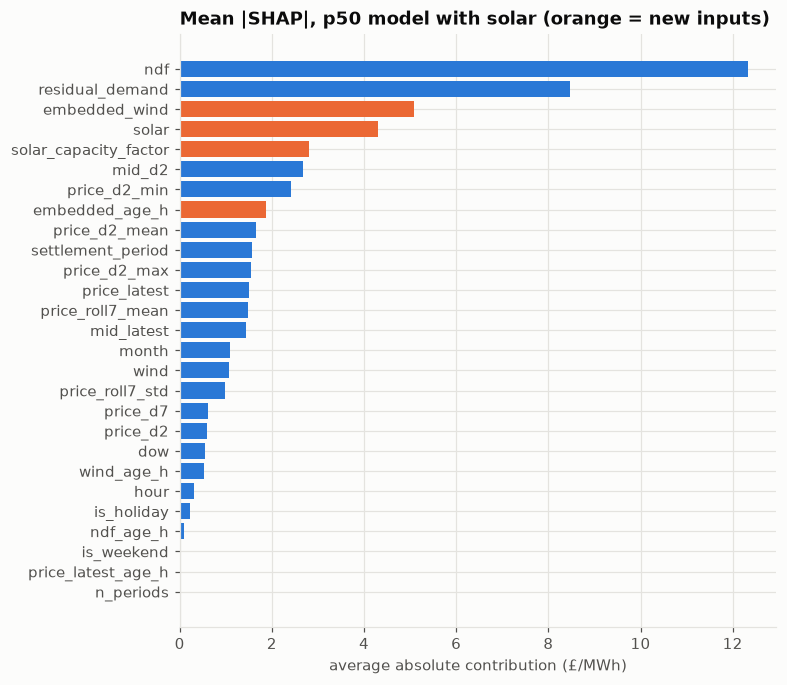

In [7]:
model = result.models["+ solar (27 inputs)"]
X_val = X.loc[X.index.get_level_values("target_date") >= VAL_START]
contrib = model.boosters["p50"].predict(X_val[model.features], pred_contrib=True)[:, :-1]
importance = pd.Series(np.abs(contrib).mean(axis=0), index=model.features).sort_values()
colors = [style.ORANGE if c in EMBEDDED_COLUMNS else style.BLUE for c in importance.index]

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(importance.index, importance.values, color=colors)
ax.set(
    title="Mean |SHAP|, p50 model with solar (orange = new inputs)",
    xlabel="average absolute contribution (£/MWh)",
)
plt.show()

## Decision

The rule, fixed before looking at the test year: adopt the new inputs if they improve £ **and**
accuracy on the validation window. The cell below states the outcome from the numbers above;
the main backtest (test year) is then re-run with the chosen inputs and logged to `experiments/`.

In [8]:
base, solar = summary.loc["baseline (23 inputs)"], summary.loc["+ solar (27 inputs)"]
adopt = solar.gbp_per_year > base.gbp_per_year and solar.mae < base.mae
print(
    f"£/yr {base.gbp_per_year:.1f} → {solar.gbp_per_year:.1f}; MAE {base.mae:.1f} → {solar.mae:.1f}; "
    f"coverage {base.coverage_80:.0%} → {solar.coverage_80:.0%}"
)
print("Decision:", "ADOPT the solar inputs" if adopt else "do NOT adopt the solar inputs")

£/yr 24.6 → 28.5; MAE 27.6 → 27.4; coverage 66% → 67%
Decision: ADOPT the solar inputs


### Reading the result honestly

- **Adopted, by the rule set in advance:** on the validation window the solar inputs raised £
  and lowered error, and section 2 shows solar is a genuine price driver that the demand
  forecast doesn't fully capture.
- **But the £ gain is small and not statistically clear:** the bootstrap interval for the
  £/year difference includes zero, so over six months part of it could be luck. The model leans
  on the new inputs heavily (SHAP), yet £ barely moves. Information that improves the *average*
  forecast doesn't automatically fix the *spread* the battery trades on (notebook 02).
- **Embedded wind matters as much as solar.** A useful surprise: wind on local networks isn't in
  the national wind forecast, and the model uses it.
- **One input to watch:** `embedded_age_h` mostly varies when NESO's archive has gaps, so the
  model may be learning a data quirk. Revisit in checkpoint C.
- The test-year result is logged in `experiments/` as `solar`, run after this decision.